In [ ]:
!pip install Pillow

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
input_dir = "/content/drive/My Drive/Antarctic_Icebergs/icebergs_bb"
output_file = "/content/drive/MyDrive/Antarctic_Icebergs/combined_annotations.geojson"

In [ ]:
#combine bounding box annotations into a single geojson file

In [ ]:
import json
import os

def combine_geojson_files(input_dir, output_file):


    combined_features = []
    for filename in os.listdir(input_dir):
        if filename.endswith(".geojson"):
            filepath = os.path.join(input_dir, filename)
            with open(filepath) as f:
                geojson_data = json.load(f)


                name = os.path.splitext(filename)[0]


                for feature in geojson_data['features']:
                    feature['properties']['name'] = name

                combined_features.extend(geojson_data['features'])

    combined_geojson = {
        "type": "FeatureCollection",
        "features": combined_features
    }

    with open(output_file, 'w') as f:
        json.dump(combined_geojson, f)

combine_geojson_files(input_dir, output_file)

pair tiff images with corrosponding bounding box

In [ ]:
import json
import os
from PIL import Image, UnidentifiedImageError

def geojson_to_coco(geojson_file, image_dir, output_file):


    with open(geojson_file) as f:
        geojson_data = json.load(f)

    coco_data = {
        "images": [],
        "annotations": [],
        "categories": [{"id": 1, "name": "iceberg"}]
    }

    annotation_id = 1
    image_id = 1

    #get tiff images
    tiff_files = [f for f in os.listdir(image_dir) if f.endswith("_reprojected.tif")]

    #dictionary for matched annotations
    paired_data = {}

    for feature in geojson_data["features"]:
        annotation_name = feature["properties"]["name"]

        #remove extension
        iceberg_id = annotation_name.replace("_bb", "")

        #find matching iceberg
        matching_tiff = next((t for t in tiff_files if iceberg_id in t), None)

        if matching_tiff:
            paired_data[matching_tiff] = feature #store matching bb

            #add feature
            image_file = os.path.join(image_dir, matching_tiff)
            try:
                with Image.open(image_file) as img:
                    width, height = img.size
            except (IOError, UnidentifiedImageError):
                print(f"Skipping unsupported or corrupted image: {matching_tiff}")
                continue  #skip to the next feature

            coco_data["images"].append({
                "id": image_id,
                "file_name": matching_tiff,
                "width": width,
                "height": height
            })
            image_id += 1
        else:
            print(f"⚠ No matching TIFF found for annotation: {iceberg_id}")

      #print matching pairs for verification
        for tiff, annotation in paired_data.items():
            print(f"✅ Matched {tiff} with annotation {annotation['properties']['name']}")

        geometry = feature['geometry']

          #geometry type set to mulitpolygon
        if geometry['type'] == 'MultiPolygon':
            for polygon_coords in geometry['coordinates']:
                #get the coordinates of the bounding box
                coordinates = polygon_coords[0]

                #convert polygon to coco segmentation format
                segmentation = [coord for point in coordinates for coord in point]

                #calculate bounding box
                min_x = min(point[0] for point in coordinates)
                min_y = min(point[1] for point in coordinates)
                max_x = max(point[0] for point in coordinates)
                max_y = max(point[1] for point in coordinates)
                bbox = [min_x, min_y, max_x - min_x, max_y - min_y]

                coco_data["annotations"].append({
                    "id": annotation_id,
                    "image_id": image_id -1 ,
                    "category_id": 1,
                    "segmentation": [segmentation],
                    "area": feature['properties'].get('area', 0),
                    "bbox": bbox,
                    "iscrowd": 0  #the annotation belongs to one object
                })
                annotation_id += 1


    with open(output_file, 'w') as f:
        json.dump(coco_data, f)

In [ ]:
geojson_file = "/content/drive/MyDrive/Antarctic_Icebergs/combined_annotations.geojson"
image_dir = "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked"
output_file = "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_coco.json"

In [ ]:
geojson_to_coco(geojson_file, image_dir, output_file)

✅ Matched A23A_001_reprojected.tif with annotation A23A_001_bb
✅ Matched A23A_001_reprojected.tif with annotation A23A_001_bb
✅ Matched A74A_001_reprojected.tif with annotation A74A_001_bb
✅ Matched A23A_001_reprojected.tif with annotation A23A_001_bb
✅ Matched A74A_001_reprojected.tif with annotation A74A_001_bb
✅ Matched A76C_001_reprojected.tif with annotation A76C_001_bb
✅ Matched A23A_001_reprojected.tif with annotation A23A_001_bb
✅ Matched A74A_001_reprojected.tif with annotation A74A_001_bb
✅ Matched A76C_001_reprojected.tif with annotation A76C_001_bb
✅ Matched B09B_001_reprojected.tif with annotation B09B_001_bb
✅ Matched A23A_001_reprojected.tif with annotation A23A_001_bb
✅ Matched A74A_001_reprojected.tif with annotation A74A_001_bb
✅ Matched A76C_001_reprojected.tif with annotation A76C_001_bb
✅ Matched B09B_001_reprojected.tif with annotation B09B_001_bb
✅ Matched A80A_001_reprojected.tif with annotation A80A_001_bb
✅ Matched A23A_001_reprojected.tif with annotation A23A

In [ ]:
#checks the keys within json file are in coco format
import json

def validate_coco_json(filepath):


    try:
        with open(filepath, 'r') as f:
            data = json.load(f)


        required_keys = ["images", "annotations", "categories"]
        if not all(key in data for key in required_keys):
            print("Missing required top-level keys:", [key for key in required_keys if key not in data])
            return False


        for image in data["images"]:
            if not all(key in image for key in ["id", "file_name", "width", "height"]):
                print("Invalid image format:", image)
                return False


        for annotation in data["annotations"]:
            if not all(key in annotation for key in ["id", "image_id", "category_id", "segmentation", "bbox", "area", "iscrowd"]):
                print("Invalid annotation format:", annotation)
                return False


        for category in data["categories"]:
            if not all(key in category for key in ["id", "name"]):
                print("Invalid category format:", category)
                return False

        return True

    except json.JSONDecodeError:
        print("Invalid JSON format.")
        return False

    except Exception as e:
        print("Error during validation:", e)
        return False


filepath = "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_coco.json"
if validate_coco_json(filepath):
    print("The JSON file is valid COCO format.")
else:
    print("The JSON file is not valid COCO format.")

The JSON file is valid COCO format.


CREATE COCO JSON FOR TEST IMAGES

In [ ]:
import json
import os
from PIL import Image

test_image_dir = "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_unseen"
test_coco_file = "/content/drive/MyDrive/Antarctic_Icebergs/test_coco.json"

coco_data = {
    "images": [],
    "annotations": [],
    "categories": [{"id": 1, "name": "iceberg"}]
}

for filename in os.listdir(test_image_dir):
    if filename.endswith(('.tif', '.tiff')):
        image_path = os.path.join(test_image_dir, filename)
        image_id = len(coco_data["images"]) + 1

        try:
            with Image.open(image_path) as img:
                width, height = img.size
        except IOError:
            print(f"Skipping unsupported or corrupted image: {filename}")
            continue

        coco_data["images"].append({
            "id": image_id,
            "file_name": filename,
            "width": width,
            "height": height
        })

with open(test_coco_file, 'w') as f:
    json.dump(coco_data, f)

Set up Detectron2

In [ ]:
!python -m pip install pyyaml==5.1
import sys, os, distutils.core
#faster way for installation
!git clone 'https://github.com/facebookresearch/detectron2'
dist = distutils.core.run_setup("./detectron2/setup.py")
!python -m pip install {' '.join([f"'{x}'" for x in dist.install_requires])}
sys.path.insert(0, os.path.abspath('./detectron2'))


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.2/274.2 kB 7.9 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
Cloning into 'detectron2'...
remote: Enumerating objects: 15837, done.
remote: Counting objects: 100% (66/66), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 15837 (delta 30), reused 12 (delta 12), pack-reused 15771 (from 2)
Receiving objects: 100% (15837/15837), 6.40 MiB | 8.67 MiB/s, done.
Resolving deltas: 100% (11532/11532), done.
Ignoring dataclasses: markers 'python_version < "3.7"' don't match your en

In [ ]:
import torch, detectron2
!nvcc --version
TORCH_VERSION = ".".join(torch.__version__.split(".")[:2])
CUDA_VERSION = torch.__version__.split("+")[-1]
print("torch: ", TORCH_VERSION, "; cuda: ", CUDA_VERSION)
print("detectron2:", detectron2.__version__)

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Thu_Jun__6_02:18:23_PDT_2024
Cuda compilation tools, release 12.5, V12.5.82
Build cuda_12.5.r12.5/compiler.34385749_0
torch:  2.6 ; cuda:  cu124
detectron2: 0.6


In [ ]:
#some basic setup:
#setup detectron2 logger
import detectron2
from detectron2.utils.logger import setup_logger
setup_logger()

#import some common libraries
import numpy as np
import os, json, cv2, random
from google.colab.patches import cv2_imshow

#import some common detectron2 utilities
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog

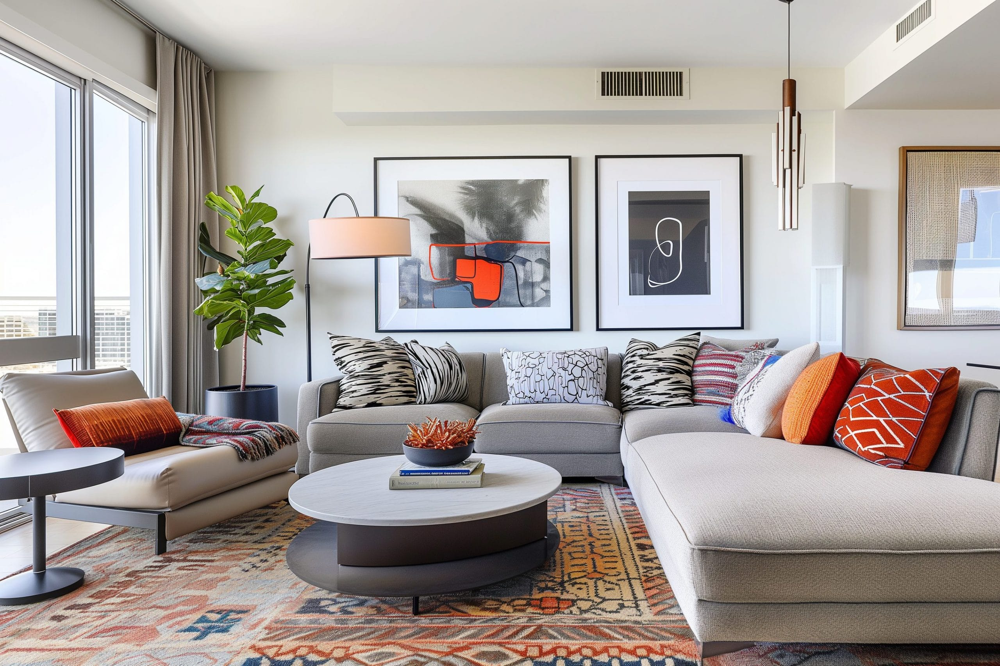

In [ ]:
im = cv2.imread("/content/drive/MyDrive/Colab Notebooks/Data/living-room-photo.jpg")
cv2_imshow(im)

In [ ]:
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  #set threshold for this model
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml") #using mask-rcnn
#set device to cpu
cfg.MODEL.DEVICE = "cpu"
predictor = DefaultPredictor(cfg)
outputs = predictor(im)

[03/24 18:10:08 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from https://dl.fbaipublicfiles.com/detectron2/COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x/137849600/model_final_f10217.pkl ...


model_final_f10217.pkl: 178MB [00:01, 99.6MB/s]                          
/usr/local/lib/python3.11/dist-packages/torch/functional.py:539: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:3637.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [ ]:
#look at the outputs - tensors and bounding boxes.
print(outputs["instances"].pred_classes)
print(outputs["instances"].pred_boxes)

tensor([58, 57, 57, 57, 45, 56, 60])
Boxes(tensor([[4.8955e+02, 4.5095e+02, 7.6523e+02, 1.1112e+03],
        [6.1471e+01, 9.6631e+02, 7.8733e+02, 1.4446e+03],
        [1.5899e+03, 8.6223e+02, 2.5527e+03, 1.6768e+03],
        [7.5599e+02, 8.5580e+02, 1.7079e+03, 1.2394e+03],
        [1.0238e+03, 1.0612e+03, 1.2256e+03, 1.1956e+03],
        [5.1837e-01, 8.5673e+02, 2.1527e+02, 9.5073e+02],
        [5.1683e-01, 1.1342e+03, 3.1751e+02, 1.5429e+03]]))


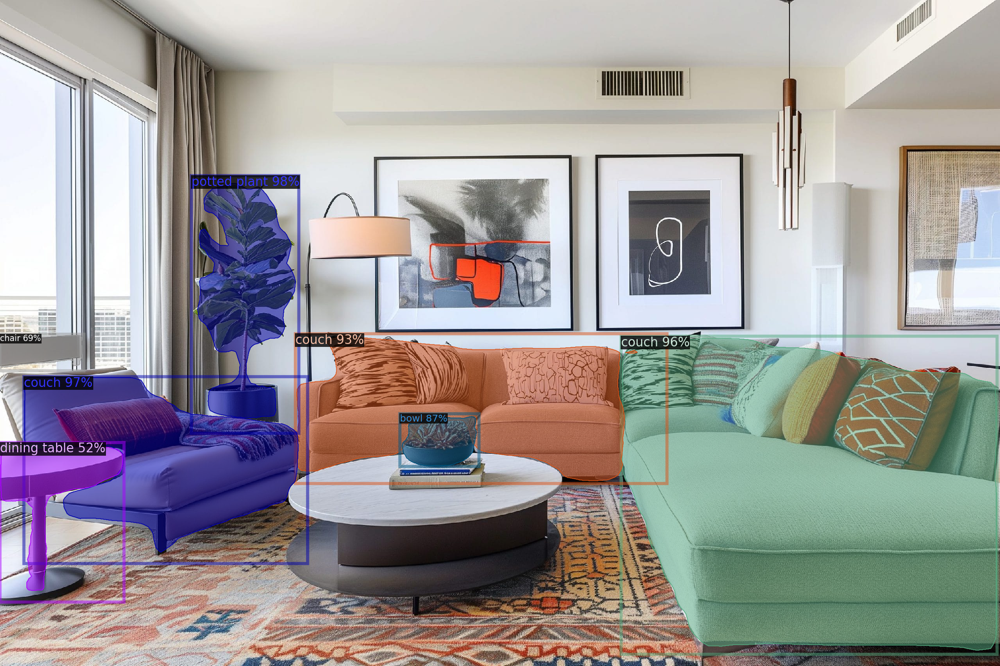

In [ ]:
#use `Visualizer` to draw the predictions on the image.
v = Visualizer(im[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.8)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
cv2_imshow(out.get_image()[:, :, ::-1])

Now test on iceberg image

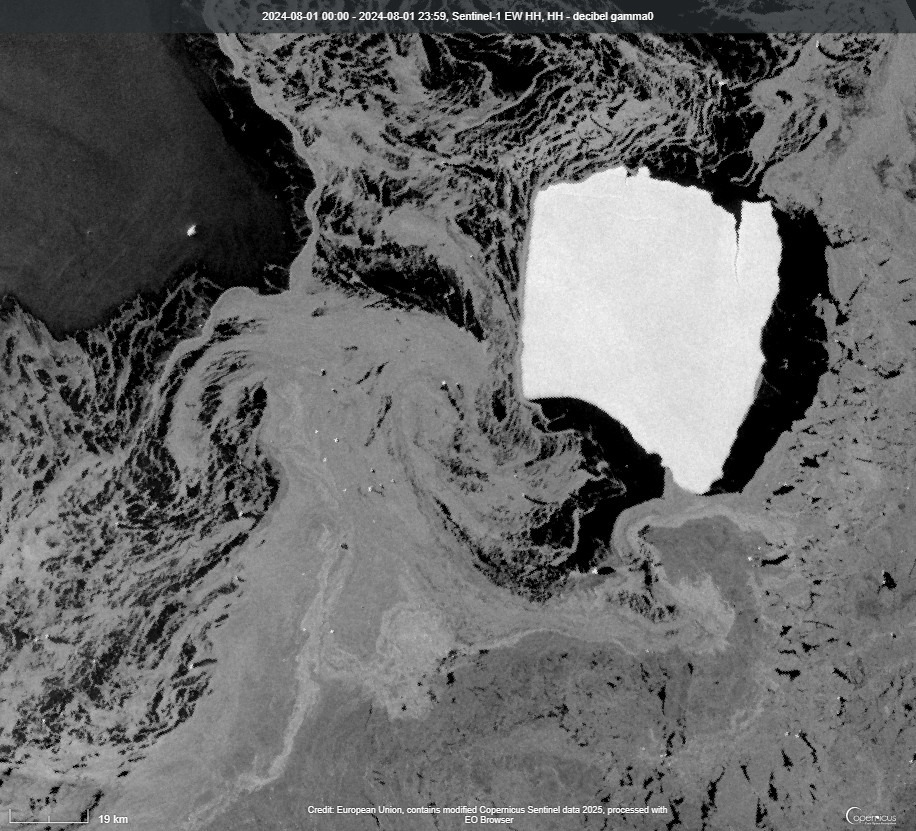

In [ ]:
ice_im = cv2.imread("/content/drive/MyDrive/Colab Notebooks/Data/A23A_001.jpg")
cv2_imshow(ice_im)

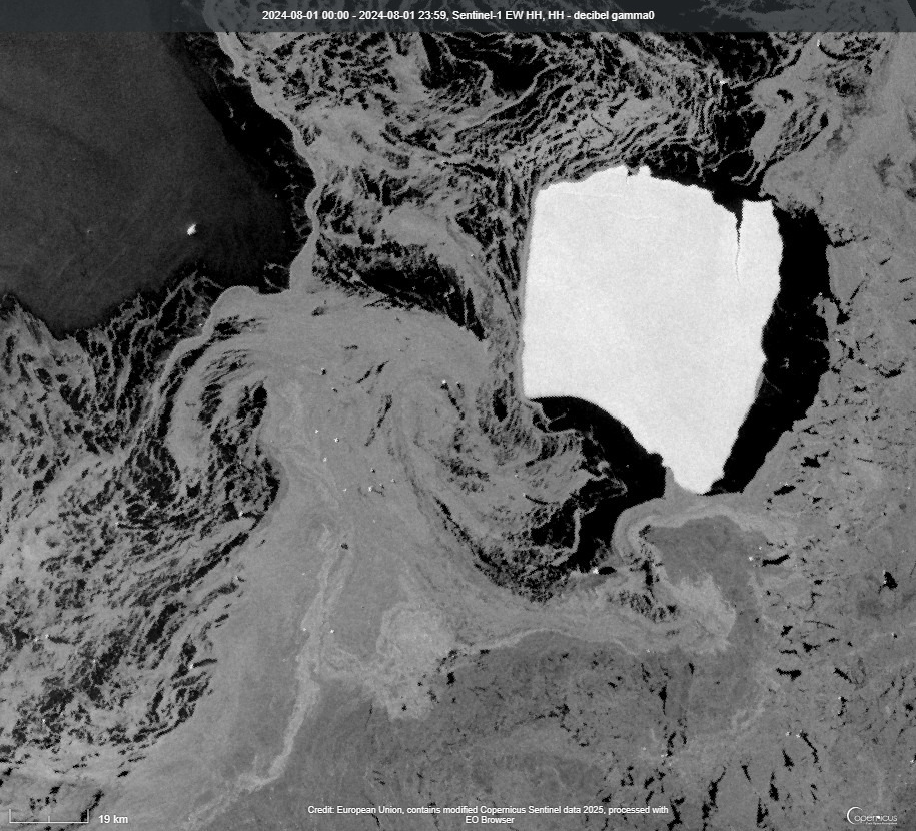

In [ ]:
ice_outputs = predictor(ice_im)
ice_v = Visualizer(ice_im[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]))
ice_out = ice_v.draw_instance_predictions(ice_outputs["instances"].to("cpu"))
cv2_imshow(ice_out.get_image()[:, :, ::-1])

No predictions were made... time to train on iceberg dataset

In [ ]:
train_image_dir = "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked"
train_coco_file = "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_coco.json"
test_image_dir = "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_unseen"
test_coco_file = "/content/drive/MyDrive/Antarctic_Icebergs/test_coco.json"

In [ ]:
import json
import os
from PIL import Image, UnidentifiedImageError  # Import Image from PIL

pixel_sum = np.zeros(3)  #initialize sum for R, G, B channels
pixel_sum_sq = np.zeros(3)  #initialize sum of squares for R, G, B channels
num_pixels = 0  #initialize total pixel count

for filename in os.listdir(train_image_dir):
    if filename.endswith(('.tif', '.tiff')):  #check for .tif or .tiff extensions
        image_path = os.path.join(train_image_dir, filename)
        try:
            with Image.open(image_path) as img:
                img_np = np.array(img)
                h, w, c = img_np.shape
                pixel_sum += np.sum(img_np, axis=(0, 1))
                pixel_sum_sq += np.sum(img_np**2, axis=(0, 1))
                num_pixels += h * w
        except IOError:
            print(f"Skipping unsupported or corrupted image: {filename}")

In [ ]:
pixel_mean = pixel_sum / num_pixels
pixel_variance = np.abs((pixel_sum_sq / num_pixels) - (pixel_mean**2))  #take absolute value
pixel_std = np.sqrt(pixel_variance)

print("Pixel Mean:", pixel_mean)
print("Pixel Standard Deviation:", pixel_std)

Pixel Mean: [55.87243249 55.87243249 55.87243249]
Pixel Standard Deviation: [55.45770568 55.45770568 55.45770568]


In [ ]:
from detectron2.data.datasets import register_coco_instances
register_coco_instances("my_dataset_train", {}, train_coco_file, train_image_dir)


In [ ]:
from detectron2.data import DatasetCatalog

# Get the dataset
dataset_dicts = DatasetCatalog.get("my_dataset_train")

# Iterate through the dataset and print bounding boxes
for data_dict in dataset_dicts:
    annotations = data_dict["annotations"]
    for annotation in annotations:
        bbox = annotation["bbox"]
        print(f"Bounding box for image {data_dict['file_name']}: {bbox}")

[04/09 15:03:07 d2.data.datasets.coco]: Loaded 10 images in COCO format from /content/drive/MyDrive/Antarctic_Icebergs/icebergs_coco.json
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A23A_001_reprojected.tif: [-2495958.899269286, 1876217.8104645864, 90444.37900342746, 101941.54582589725]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A74A_001_reprojected.tif: [-1908066.8489674677, 1179480.7144444254, 52809.94490776118, 65504.64320289623]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A76C_001_reprojected.tif: [-2346425.5653262828, 1556517.6866542604, 38464.60888148006, 24587.18136345572]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/B09B_001_reprojected.tif: [1539766.3101867766, -2129743.5689472635, 54727.04329646262, 41571.50404250552]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A80A_001_reprojected.ti

In [ ]:
!pip install rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 72.0 MB/s eta 0:00:00


In [ ]:
import rasterio
from detectron2.data import DatasetCatalog

dataset_dicts = DatasetCatalog.get("my_dataset_train")

for data_dict in dataset_dicts:
    image_path = data_dict["file_name"]

    # Open the GeoTIFF image with rasterio
    with rasterio.open(image_path) as dataset:
        # Get the image's geospatial transform
        transform = dataset.transform

        # Iterate through annotations and convert coordinates
        for annotation in data_dict["annotations"]:
            bbox = annotation["bbox"]  # Original bbox in geographic coordinates
            x_min, y_min, width, height = bbox
            #Note: This might be slightly inaccurate, but try the following:
            # Create corner points of the bounding box
            top_left = (x_min, y_min + height)
            bottom_right = (x_min + width, y_min)

            # Convert to pixel coordinates using the image's transform
            col_min, row_min = ~transform * top_left
            col_max, row_max = ~transform * bottom_right
            row_min, col_min, row_max, col_max = int(row_min), int(col_min), int(row_max), int(col_max)

            # Update the annotation with pixel coordinates
            annotation["bbox"] = [col_min, row_min, col_max - col_min, row_max - row_min]
            #Assuming BoxMode.XYWH_ABS remains unchanged.


# Now your dataset_dicts should have bounding boxes in image pixel coordinates

[04/09 15:03:14 d2.data.datasets.coco]: Loaded 10 images in COCO format from /content/drive/MyDrive/Antarctic_Icebergs/icebergs_coco.json


In [ ]:
from detectron2.data import DatasetCatalog


# Iterate through the dataset and print bounding boxes
for data_dict in dataset_dicts:
    annotations = data_dict["annotations"]
    for annotation in annotations:
        bbox = annotation["bbox"]
        print(f"Bounding box for image {data_dict['file_name']}: {bbox}")

Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A23A_001_reprojected.tif: [684, 438, 183, 206]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A74A_001_reprojected.tif: [462, 648, 153, 190]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A76C_001_reprojected.tif: [535, 750, 173, 111]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/B09B_001_reprojected.tif: [578, 618, 265, 201]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A80A_001_reprojected.tif: [612, 689, 102, 98]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A81_001_reprojected.tif: [531, 620, 226, 240]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A83_001_reprojected.tif: [661, 547, 132, 164]
Bounding box for image /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/B22A_001_r

In [ ]:
from detectron2.data.datasets import register_coco_instances

# Assuming you have 'dataset_dicts' with the converted coordinates

# Re-register the dataset with the updated coordinates
register_coco_instances("my_dataset_train", {}, "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_coco.json", "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked")

In [ ]:
for data in dataset_dicts:
    print(f"\nImage: {data['file_name']}")
    with rasterio.open(data["file_name"]) as src:
        height, width = src.height, src.width
        print(f"Image shape: {width} x {height}")

    for ann in data["annotations"]:
        x, y, w, h = ann["bbox"]
        print(f"BBox: x={x}, y={y}, w={w}, h={h}")
        print(f"    → x+w: {x+w}, y+h: {y+h}")



Image: /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A23A_001_reprojected.tif
Image shape: 1414 x 1470
BBox: x=684, y=438, w=183, h=206
    → x+w: 867, y+h: 644

Image: /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A74A_001_reprojected.tif
Image shape: 1347 x 1473
BBox: x=462, y=648, w=153, h=190
    → x+w: 615, y+h: 838

Image: /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A76C_001_reprojected.tif
Image shape: 1333 x 1472
BBox: x=535, y=750, w=173, h=111
    → x+w: 708, y+h: 861

Image: /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/B09B_001_reprojected.tif
Image shape: 1460 x 1383
BBox: x=578, y=618, w=265, h=201
    → x+w: 843, y+h: 819

Image: /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A80A_001_reprojected.tif
Image shape: 1338 x 1473
BBox: x=612, y=689, w=102, h=98
    → x+w: 714, y+h: 787

Image: /content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A81_001_reprojected.tif
Image shape: 1391 x 1461
BBox

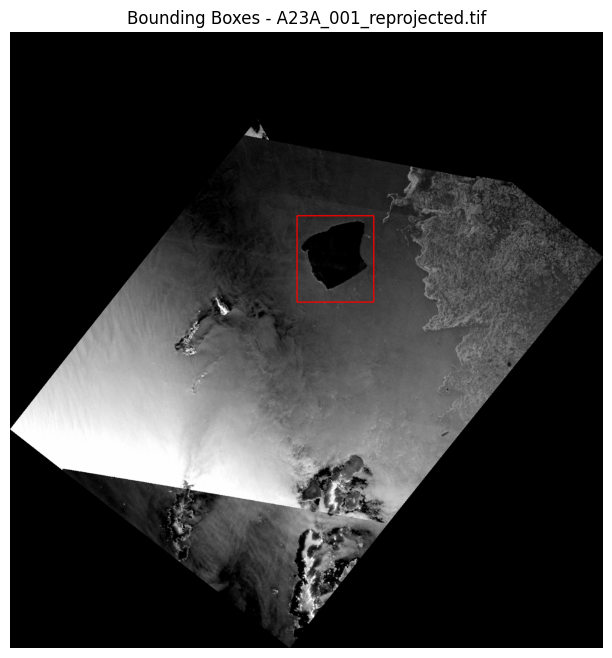

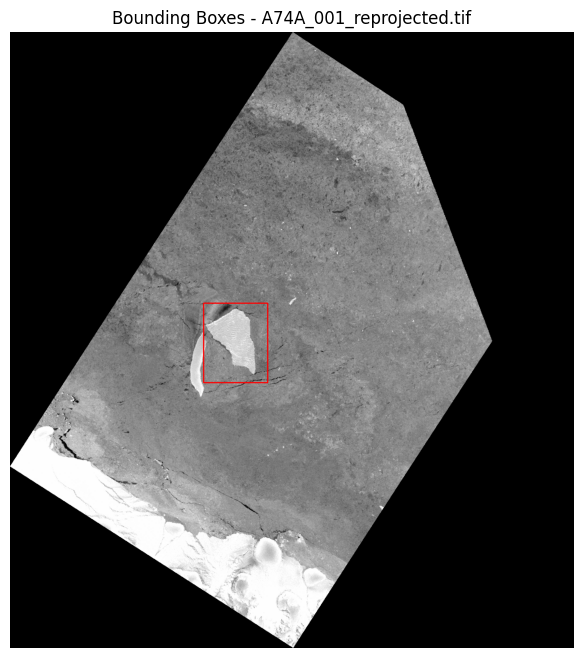

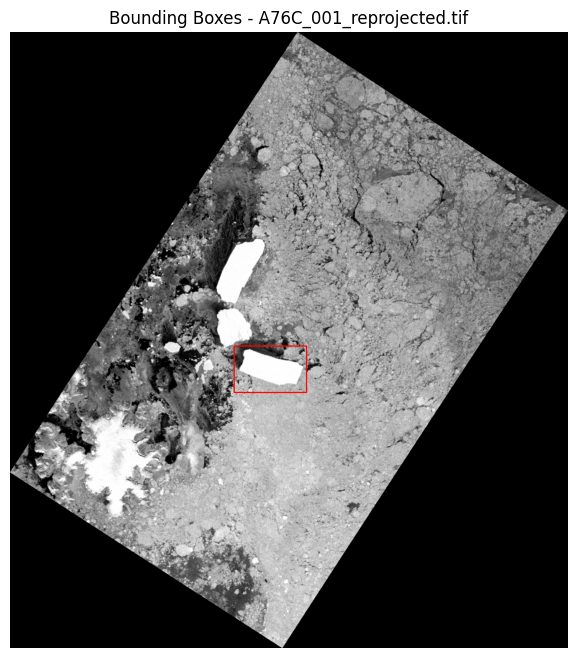

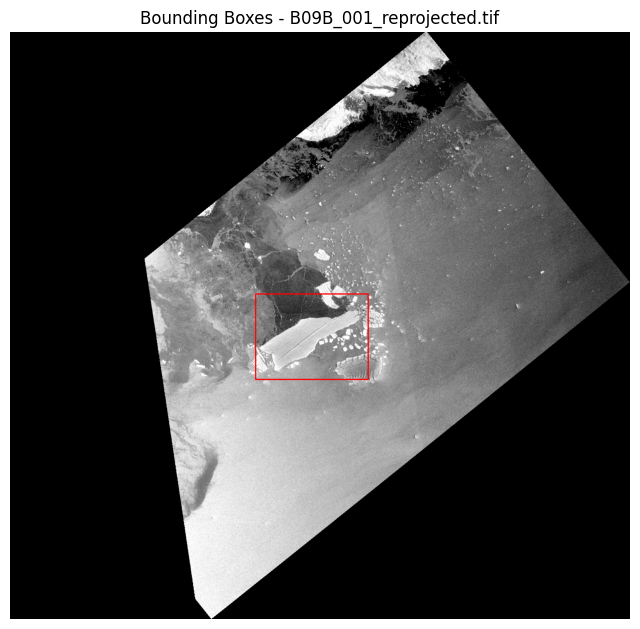

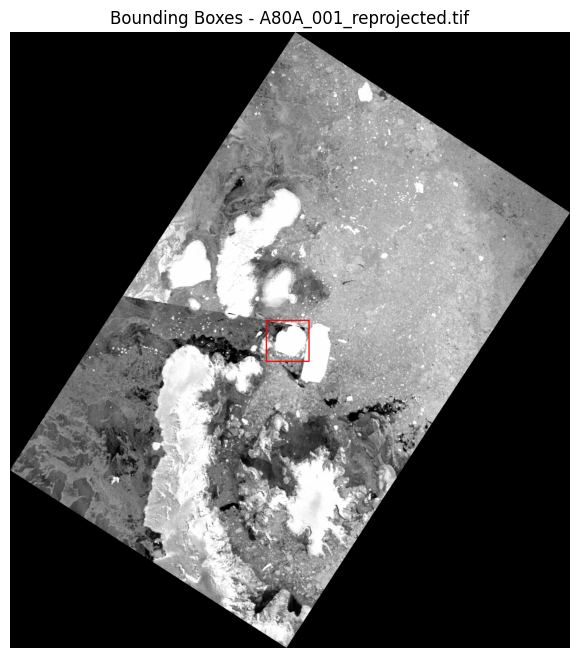

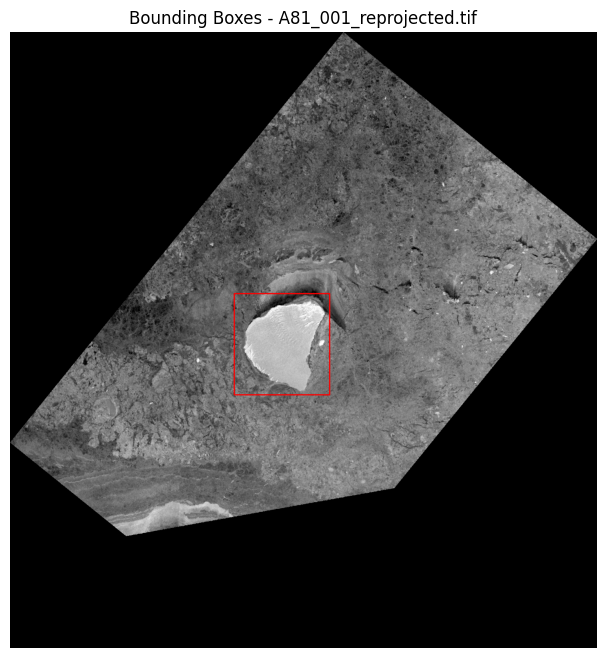

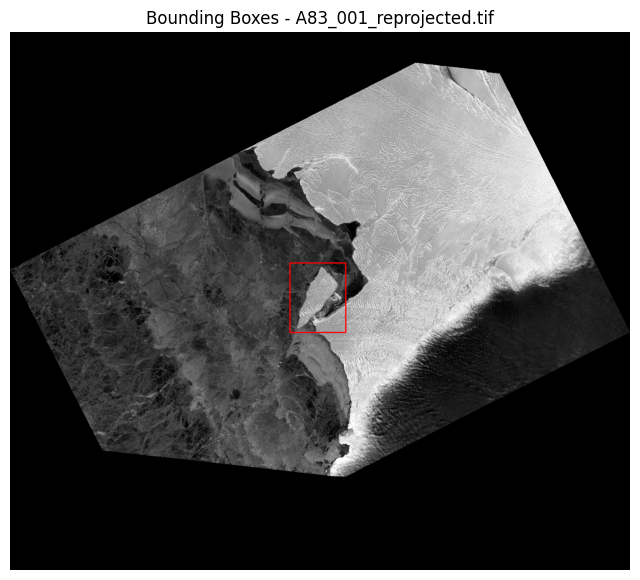

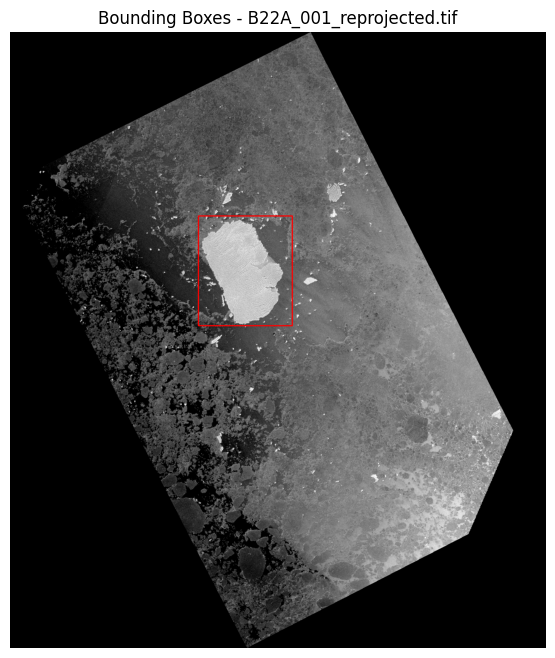

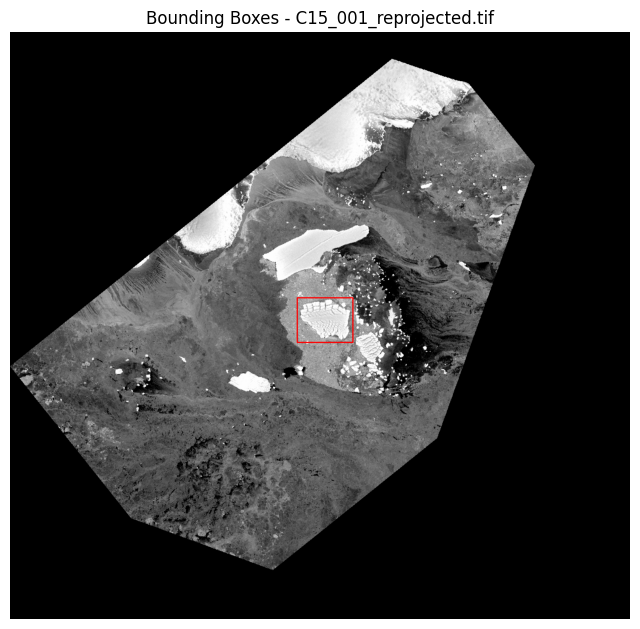

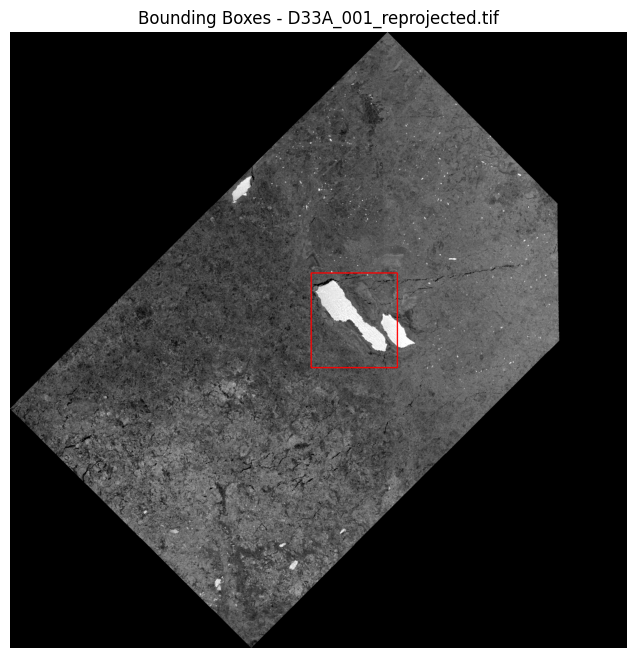

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import rasterio
from detectron2.data import DatasetCatalog

#dataset_dicts = DatasetCatalog.get("my_dataset_train")

for data in dataset_dicts:
    image_path = data["file_name"]

    # Open image using rasterio
    with rasterio.open(image_path) as src:
        # Read the first 3 bands if they exist, else fallback to grayscale
        count = src.count
        if count >= 3:
            image = src.read([1, 2, 3])  # RGB bands
            image = np.transpose(image, (1, 2, 0))  # HWC format
        else:
            image = src.read(1)  # Single-band grayscale
            image = np.stack([image]*3, axis=-1)  # Make it 3-channel grayscale

    # Normalize to 0–255 and convert to uint8
    image = (255 * ((image - image.min()) / (np.ptp(image) + 1e-8))).astype("uint8")

    # Ensure it's a proper array for OpenCV
    image_cv = image.copy()

    # Draw bounding boxes
    for ann in data["annotations"]:
        x, y, w, h = ann["bbox"]
        start_point = (int(x), int(y))
        end_point = (int(x + w), int(y + h))
        cv2.rectangle(image_cv, start_point, end_point, (255, 0, 0), 2)

    # Show image with matplotlib
    plt.figure(figsize=(8, 8))
    plt.imshow(image_cv)
    plt.title(f"Bounding Boxes - {image_path.split('/')[-1]}")
    plt.axis('off')
    plt.show()



In [ ]:
train_metadata = MetadataCatalog.get("my_dataset_train")
train_dataset_dicts = DatasetCatalog.get("my_dataset_train")

[04/09 15:03:42 d2.data.datasets.coco]: Loaded 10 images in COCO format from /content/drive/MyDrive/Antarctic_Icebergs/icebergs_coco.json


Configuration

Train

In [ ]:
import copy
import torch
import os
from detectron2 import utils
from detectron2.data import DatasetCatalog, DatasetMapper
from detectron2.data.datasets import register_coco_instances
from detectron2.engine import DefaultTrainer
from detectron2.config import get_cfg
from detectron2 import model_zoo
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Custom DatasetMapper with Albumentations
class AlbumentationsMapper(DatasetMapper):
    def __init__(self, cfg, is_train=True):
        super().__init__(cfg, is_train=is_train)
        self.aug = A.Compose([
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], max_pixel_value=255.0),
            ToTensorV2()
        ])

    def __call__(self, dataset_dict):
        dataset_dict = copy.deepcopy(dataset_dict)  # it will be modified by code below
        image = utils.read_image(dataset_dict["file_name"], format=self.image_format)
        utils.check_image_size(dataset_dict, image)
        image = self.aug(image=np.array(image))["image"]
        image_shape = image.shape[:2]  # h, w
        # Pytorch requires channel first.
        dataset_dict["image"] = torch.as_tensor(np.ascontiguousarray(image.transpose(2, 0, 1)))
        # Rebuild boxes if your augmentation changes the boxes
        annos = [
            utils.transform_instance_annotations(
                obj, transforms=[], image_size=image_shape,
            )
            for obj in dataset_dict.pop("annotations")
            if obj.get("iscrowd", 0) == 0
        ]
        instances = utils.annotations_to_instances(
            annos, image_shape, mask_format=self.mask_format
        )
        # Create a tight bounding box from masks, useful when image is cropped
        if self.crop_gen and instances.has("gt_masks"):
            instances.gt_boxes = instances.gt_masks.get_bounding_boxes()
        dataset_dict["instances"] = utils.filter_empty_instances(instances)
        return dataset_dict

# Create output directory
os.makedirs("/content/drive/MyDrive/Colab Notebooks/models/Detectron2_Models", exist_ok=True)

# Register dataset (make sure your dataset is in the correct format)
register_coco_instances("my_dataset_train", {}, "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_coco.json", "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked")

# Load configuration
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"))

# Set up dataset and training settings
cfg.DATASETS.TRAIN = ("my_dataset_train",)
cfg.DATASETS.TEST = ()  # Empty tuple, no test dataset
cfg.TEST.EVAL_PERIOD = 0  # Disable evaluation, since no validation set is provided

# Model settings
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1  # Only one class (icebergs)

# Data loader settings
cfg.DATALOADER.NUM_WORKERS = 0
cfg.SOLVER.STEPS = []  # No learning rate decay
cfg.SOLVER.MAX_ITER = 300  # Total number of iterations
cfg.SOLVER.BASE_LR = 0.0001  # Learning rate for small dataset
cfg.SOLVER.IMS_PER_BATCH = 1  # Batch size (1 to avoid memory issues)

# ROI head settings
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128  # Adjust based on available GPU memory
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1  # Icebergs only

# Output directory for model checkpoints and logs
cfg.OUTPUT_DIR = "/content/drive/MyDrive/Colab Notebooks/models/Detectron2_Models"

# Set device to CPU (or "cuda" if you have a GPU)
cfg.MODEL.DEVICE = "cpu"

# Initialize trainer and start training
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)  # Don't resume from checkpoint if not available
trainer.train()


[04/09 15:03:48 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

R-50.pkl: 102MB [00:01, 61.8MB/s]                            


[04/09 15:03:50 d2.checkpoint.c2_model_loading]: Renaming Caffe2 weights ......
[04/09 15:03:50 d2.checkpoint.c2_model_loading]: Following weights matched with submodule backbone.bottom_up - Total num: 54


backbone.fpn_lateral2.{bias, weight}
backbone.fpn_lateral3.{bias, weight}
backbone.fpn_lateral4.{bias, weight}
backbone.fpn_lateral5.{bias, weight}
backbone.fpn_output2.{bias, weight}
backbone.fpn_output3.{bias, weight}
backbone.fpn_output4.{bias, weight}
backbone.fpn_output5.{bias, weight}
proposal_generator.rpn_head.anchor_deltas.{bias, weight}
proposal_generator.rpn_head.conv.{bias, weight}
proposal_generator.rpn_head.objectness_logits.{bias, weight}
roi_heads.box_head.fc1.{bias, weight}
roi_heads.box_head.fc2.{bias, weight}
roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
  fc1000.{bias, weight}
  stem.conv1.bias


[04/09 15:03:50 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.11/dist-packages/torch/functional.py:539: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:3637.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[04/09 15:06:24 d2.utils.events]:  eta: 0:35:11  iter: 19  total_loss: 1.125  loss_cls: 0.4612  loss_box_reg: 0  loss_rpn_cls: 0.6637  loss_rpn_loc: 0    time: 7.5899  last_time: 10.1293  data_time: 0.1144  last_data_time: 0.1002   lr: 6.427e-06  max_mem: 0M
[04/09 15:08:58 d2.utils.events]:  eta: 0:31:51  iter: 39  total_loss: 0.7966  loss_cls: 0.1408  loss_box_reg: 0  loss_rpn_cls: 0.6534  loss_rpn_loc: 0    time: 7.5439  last_time: 6.5638  data_time: 0.1068  last_data_time: 0.1551   lr: 1.3087e-05  max_mem: 0M
[04/09 15:11:22 d2.utils.events]:  eta: 0:29:24  iter: 59  total_loss: 0.6762  loss_cls: 0.05184  loss_box_reg: 0  loss_rpn_cls: 0.6294  loss_rpn_loc: 0    time: 7.4217  last_time: 6.1697  data_time: 0.1059  last_data_time: 0.0924   lr: 1.9747e-05  max_mem: 0M
[04/09 15:14:00 d2.utils.events]:  eta: 0:27:21  iter: 79  total_loss: 0.6326  loss_cls: 0.04218  loss_box_reg: 0  loss_rpn_cls: 0.591  loss_rpn_loc: 0    time: 7.5461  last_time: 9.9565  data_time: 0.1071  last_data_tim

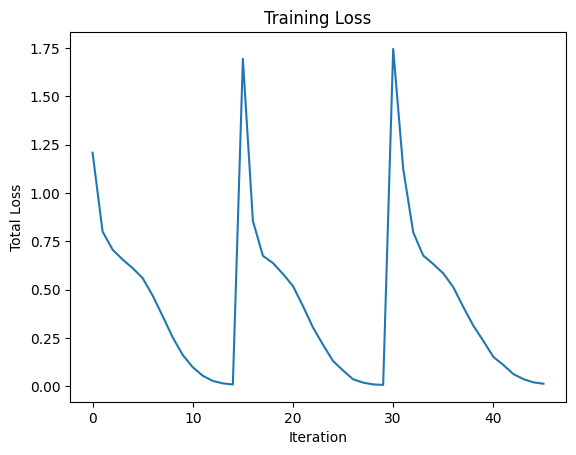

In [ ]:
import matplotlib.pyplot as plt
import json

metrics_file = "/content/drive/MyDrive/Colab Notebooks/models/Detectron2_Models/metrics.json"

total_losses = []
with open(metrics_file, 'r') as f:
    for line in f:  # Read the file line by line
        try:
            data = json.loads(line)  # Try to parse each line as JSON
            if 'total_loss' in data:
                total_losses.append(data['total_loss'])
        except json.JSONDecodeError:
            pass  # Skip lines that aren't valid JSON

plt.plot(total_losses)
plt.title("Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Total Loss")
plt.show()

Inference

In [ ]:
import os

[04/09 16:18:01 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/drive/MyDrive/Colab Notebooks/models/Detectron2_Models/model_final.pth ...


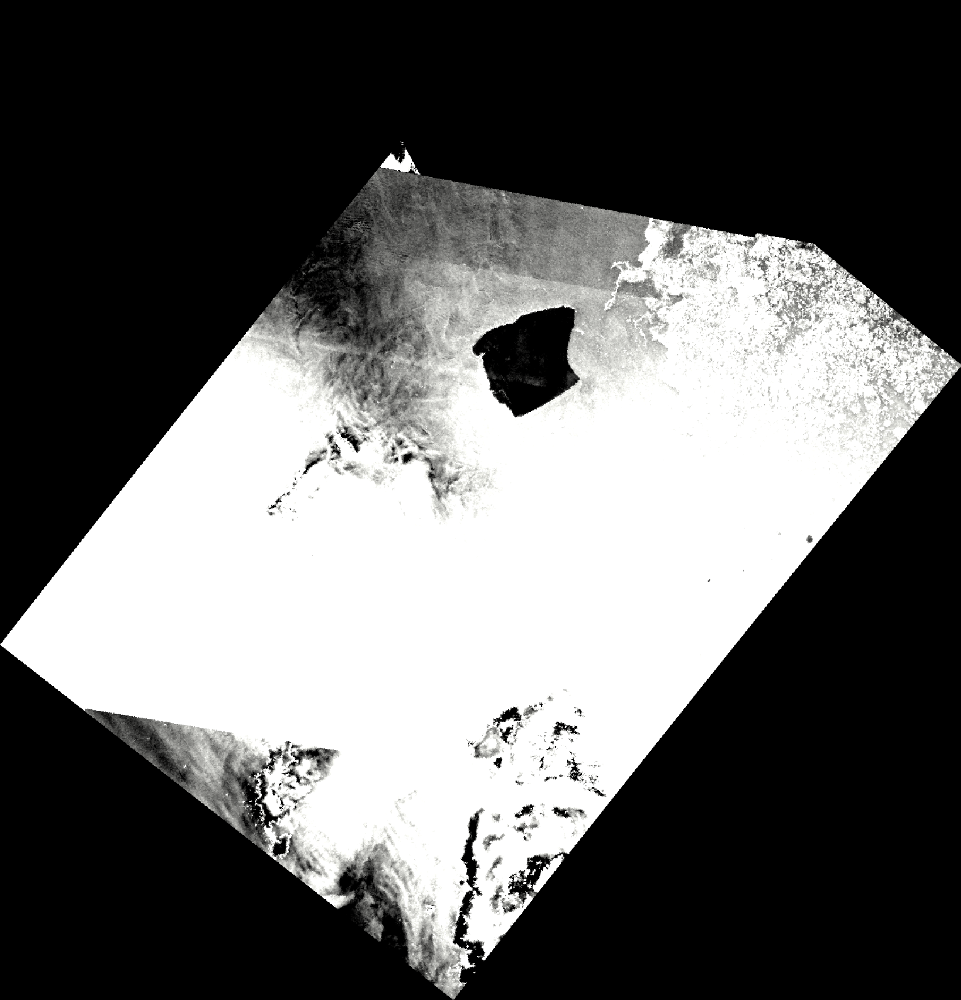

In [ ]:
import cv2
import numpy as np
import tifffile
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog
from google.colab.patches import cv2_imshow  # Import cv2_imshow for Colab

# Set up the config
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"))
cfg.MODEL.WEIGHTS = "/content/drive/MyDrive/Colab Notebooks/models/Detectron2_Models/model_final.pth"  # Trained model path
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1  # Only iceberg class
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.3  # Score threshold for predictions
cfg.MODEL.DEVICE = "cpu"  # Or "cuda" for GPU

# Initialize predictor
predictor = DefaultPredictor(cfg)

# Load TIFF image (use tifffile or PIL)
image_path = "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A23A_001_reprojected.tif"  # Replace with your image path
im = tifffile.imread(image_path)  # Reading TIFF image

# Ensure image is in the correct format for model
im = im / 255.0  # Normalize pixel values
im = (im - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]  # Normalize like during training

# Run inference
outputs = predictor(im)

# Check if the outputs have the correct structure
if "instances" in outputs:
    instances = outputs["instances"]
else:
    raise ValueError("Inference output does not contain 'instances'")

# Visualize predictions
metadata = MetadataCatalog.get("my_dataset_train")
v = Visualizer(im[:, :, ::-1], metadata=metadata, scale=1.2)

# Draw the predicted instances
v = v.draw_instance_predictions(instances.to("cpu"))

# Get the image with predictions
output_image = v.get_image()[:, :, ::-1]

# Show the image with predictions using cv2_imshow
cv2_imshow(output_image)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [ ]:
print(instances.pred_boxes)
print(instances.pred_classes)
print(instances.scores)


Boxes(tensor([], size=(0, 4)))
tensor([], dtype=torch.int64)
tensor([])


[04/09 16:23:37 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/drive/MyDrive/Colab Notebooks/models/Detectron2_Models/model_final.pth ...


roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}


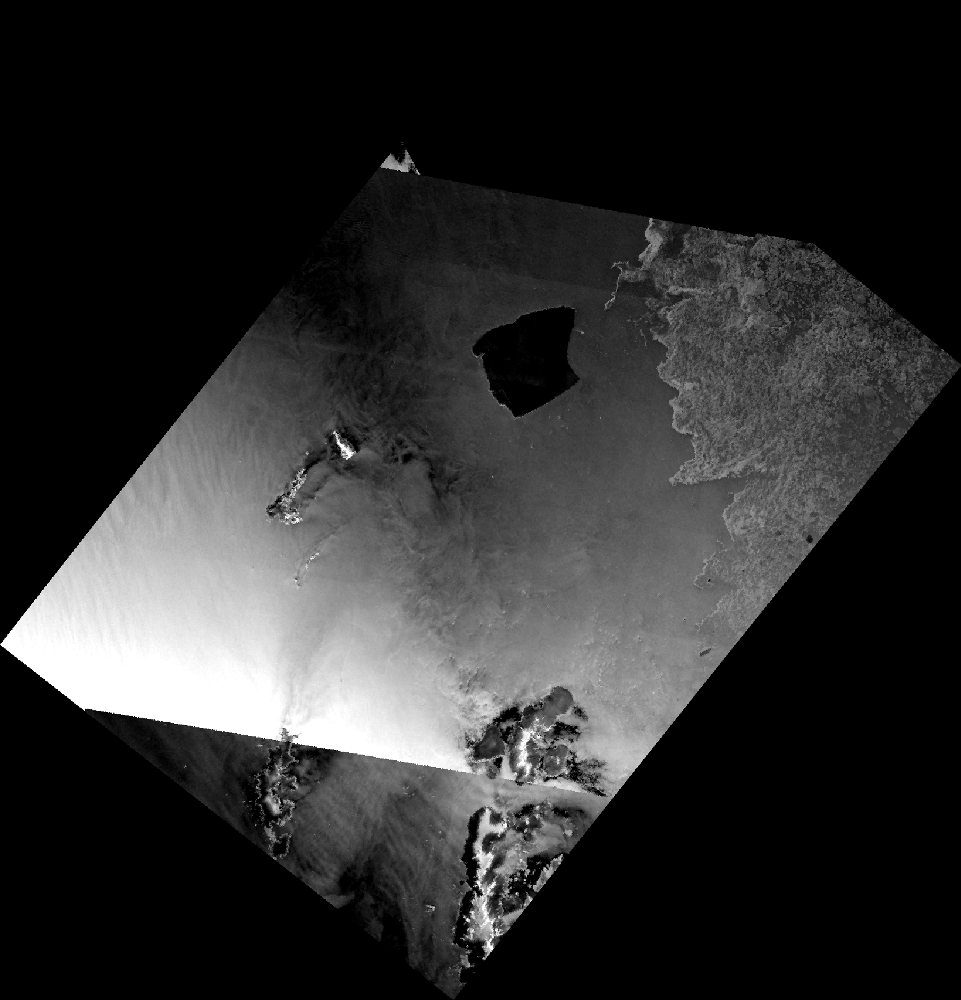

In [ ]:
import cv2
import torch
import numpy as np
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog
from google.colab.patches import cv2_imshow
import albumentations as A
from albumentations.pytorch import ToTensorV2
from PIL import Image

# Setup Albumentations normalization pipeline (same as during training)
aug = A.Compose([
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], max_pixel_value=255.0),
    ToTensorV2()
])

# Load your trained model
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"))
cfg.MODEL.WEIGHTS = "/content/drive/MyDrive/Colab Notebooks/models/Detectron2_Models/model_final.pth"  # Update with your model path
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  # Adjust threshold for visualization

# Initialize the predictor
predictor = DefaultPredictor(cfg)

# Load the TIFF image for inference using PIL (better handling of TIFF)
image_path = "/content/drive/MyDrive/Antarctic_Icebergs/icebergs_unmasked/A23A_001_reprojected.tif"  # Update with your TIFF image path
image_pil = Image.open(image_path)
image = np.array(image_pil)  # Convert PIL image to NumPy array

# Apply the same normalization and convert to Tensor
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert to RGB for correct input
image_aug = aug(image=image_rgb)  # Apply the augmentation (normalization)
image_tensor = image_aug["image"]  # This is a tensor now, but we need to pass NumPy to the predictor

# Convert the tensor back to a NumPy array (for input to the predictor)
image_np = image_tensor.permute(1, 2, 0).numpy()  # Convert from (C, H, W) to (H, W, C)

# Run the model on the input image (NumPy array)
outputs = predictor(image_np)  # Inference

# Extract the predicted instances (bounding boxes, scores, etc.)
instances = outputs["instances"].to("cpu")
pred_boxes = instances.pred_boxes.tensor.numpy()
pred_classes = instances.pred_classes.numpy()
pred_scores = instances.scores.numpy()

# Optionally, filter out predictions below a certain score threshold
threshold = 0.5  # You can adjust this value
filtered_indices = pred_scores > threshold
pred_boxes = pred_boxes[filtered_indices]
pred_classes = pred_classes[filtered_indices]
pred_scores = pred_scores[filtered_indices]

# Visualize the predictions on the image
metadata = MetadataCatalog.get("my_dataset_train")  # Replace with your dataset
v = Visualizer(image[:, :, ::-1], metadata=metadata, scale=1.2)
v = v.draw_instance_predictions(instances[filtered_indices])

# Get the output image and display it using cv2_imshow (for Google Colab)
output_image = v.get_image()[:, :, ::-1]
cv2_imshow(output_image)  # Display the image with predictions
